# 02 - Feature engineering
Every demand-derived feature is shifted >= 28 days (the forecast horizon) so one model can predict all 28 days directly with **no leakage**. Price, calendar, SNAP and event-distance features are known in advance and used unshifted.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
from src.config import connect, SCHEMA
con = connect(read_only=True)

In [2]:
from src.features.build_features import load_panel, add_features, BASE_FEATURES, EVENT_FEATURES
panel = load_panel(con)
feats = add_features(panel)
print(feats.shape)
feats[['date','item_id','store_id','units']+BASE_FEATURES[:8]+EVENT_FEATURES].dropna().head()

(560000, 32)


,date,item_id,store_id,units,lag_28,lag_35,lag_42,lag_364,roll_mean_7,roll_mean_28,roll_mean_56,roll_std_28,days_to_event,days_since_event,pre_holiday_window
364,2021-12-31,FOODS_1_001,CA_1,2.000,5.000,0.000,3.000,1.000,1.857,1.643,1.661,1.704,1,6,1
365,2022-01-01,FOODS_1_001,CA_1,2.000,0.000,2.000,7.000,1.000,1.571,1.464,1.625,1.598,0,0,1
366,2022-01-02,FOODS_1_001,CA_1,0.000,2.000,2.000,0.000,3.000,1.571,1.464,1.643,1.598,14,1,0
367,2022-01-03,FOODS_1_001,CA_1,2.000,1.000,1.000,1.000,3.000,1.571,1.464,1.625,1.598,14,2,0
368,2022-01-04,FOODS_1_001,CA_1,2.000,2.000,1.000,0.000,3.000,1.714,1.464,1.607,1.598,14,3,0


## Leakage check
The unit test `tests/test_features.py::test_no_leakage_...` perturbs demand at day *t* and asserts no demand feature changes for days *t..t+27*. Here is the same idea on real data:

In [3]:
s = feats[(feats.item_id==feats.item_id.iloc[0])&(feats.store_id=='CA_1')].reset_index(drop=True)
assert (s.lag_28.iloc[28:] .values == s.units.shift(28).iloc[28:].values)[~np.isnan(s.lag_28.iloc[28:].values)].all()
print('lag_28 aligned with units shifted by 28 days: OK')

lag_28 aligned with units shifted by 28 days: OK


## Feature importance (final LightGBM, last cutoff)

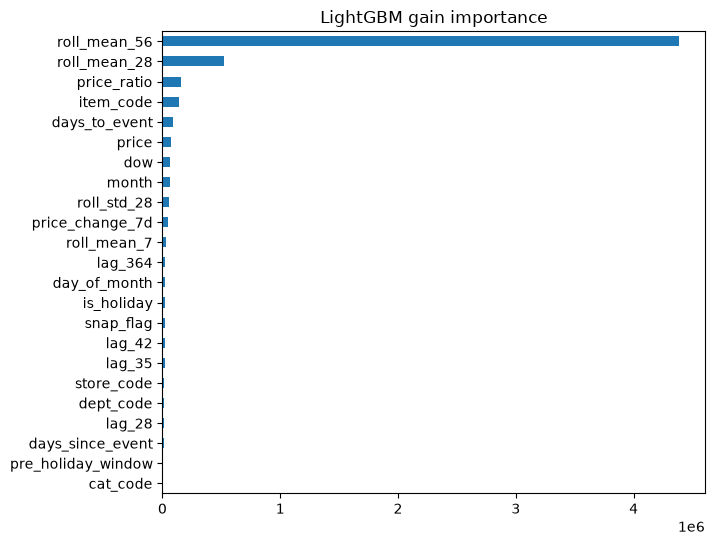

In [4]:
import lightgbm as lgb
from src.models.train import LGB_PARAMS, LGB_MODELS
cols = LGB_MODELS['lightgbm']
cut = feats.date.max() - pd.Timedelta(days=28)
tr = feats[(feats.date<=cut)&feats.units.notna()]
m = lgb.LGBMRegressor(**LGB_PARAMS).fit(tr[cols], tr.units)
pd.Series(m.booster_.feature_importance('gain'), index=cols).sort_values().plot.barh(figsize=(7,6), title='LightGBM gain importance'); plt.show()